# Fleire eksempel på dataanalyse

Denne notatboka byggjer vidare på `tolke-ute.ipynb` og `tolke-v2.ipynb`. Her lærer du å

1. rydde i data (fjerne målingar som ikkje høyrer heime),
2. finne hol i dataa,
3. lage døgn- og timestatistikk med `resample`,
4. finne døgnvariasjonen med `groupby`,
5. sjå etter samanhengar med spreiingsplott,
6. lage histogram,
7. samanlikne to verstasjonar (inne og ute),
8. lagre resultat til fil.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 4)

data = pd.read_csv("utestasjon-bones.csv", parse_dates=["dato"], index_col="dato")

## 1. Rydde i data

Ser me på temperaturen dei første timane, er det tydeleg at noko er rart: stasjonen målte rundt 26 °C før temperaturen plutseleg fall. Stasjonen stod truleg inne før han vart sett ut. Desse målingane må me fjerne, elles blir til dømes maksimumstemperaturen feil.

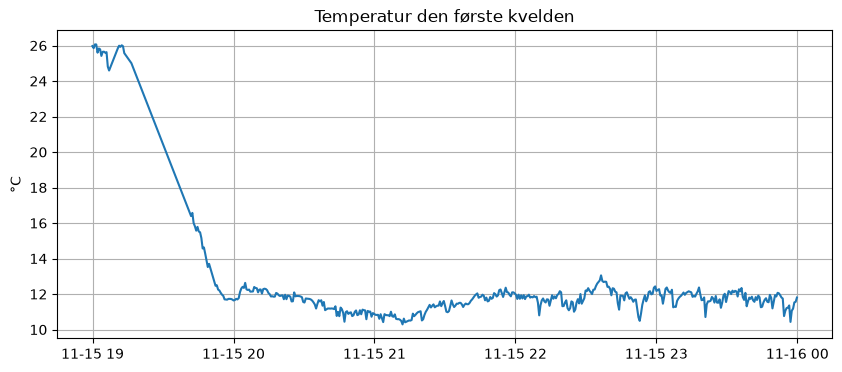

In [2]:
start = data.loc["2022-11-15"]
plt.plot(start.index, start["temperatur"])
plt.title("Temperatur den første kvelden")
plt.ylabel("°C")
plt.grid()
plt.show()

In [3]:
print("Maks temperatur FØR rydding:", data["temperatur"].max())

# Me tek berre med målingar frå stasjonen var komen ut
data = data.loc["2022-11-15 19:45":]

print("Maks temperatur ETTER rydding:", data["temperatur"].max())

Maks temperatur FØR rydding: 26.063973628074326
Maks temperatur ETTER rydding: 15.521467112950102


## 2. Finne hol i dataa

Stasjonen skulle måle kvart 33. sekund. Med `diff()` finn me tida mellom kvar måling. Er tida mykje lengre, manglar det data, til dømes fordi straumen eller nettverket var borte.

In [4]:
mellomrom = data.index.to_series().diff()  # Tid sidan førre måling
hol = mellomrom[mellomrom > pd.Timedelta("30min")]
print(f"Fann {len(hol)} hol på meir enn 30 minutt:")
hol

Fann 9 hol på meir enn 30 minutt:


dato
2022-11-17 16:34:01.375301   0 days 16:04:05.692550
2022-11-17 23:42:37.548783   0 days 02:09:31.703955
2022-11-18 07:09:04.788363   0 days 07:11:03.107358
2022-11-23 00:11:46.777841   0 days 03:14:00.105632
2022-11-26 22:59:08.952597   0 days 20:21:30.230659
2022-11-30 07:40:58.222003   0 days 05:37:49.881061
2022-12-02 12:52:12.123390   0 days 01:36:20.951947
2022-12-02 14:12:09.088303   0 days 01:15:00.161592
2022-12-02 21:29:58.537511   0 days 01:50:18.547503
Name: dato, dtype: timedelta64[us]

## 3. Døgn- og timestatistikk med `resample`

`resample("D")` samlar alle målingane frå same døgn, og så kan me rekne ut til dømes snitt, minimum og maksimum. `"60min"` gir timar, `"W"` gir veker.

Kolonna `count` viser kor mange målingar det er i kvart døgn. Eit fullt døgn har rundt 2600 målingar, så døgn med mykje færre manglar data. Snittet for slike døgn er mindre til å stole på.

In [5]:
dogn = data["temperatur"].resample("D").agg(["mean", "min", "max", "count"]).round(1)
dogn

,mean,min,max,count
dato,,,,
2022-11-15,11.7,10.3,15.5,465
2022-11-16,11.0,7.7,14.9,2622
2022-11-17,6.0,3.4,9.5,630
2022-11-18,4.3,0.9,10.0,1840
2022-11-19,1.5,-1.4,6.9,2621
2022-11-20,0.4,-1.9,4.4,2621
2022-11-21,1.3,-2.9,4.9,2615
2022-11-22,3.2,0.3,7.3,2286
2022-11-23,8.3,4.3,12.1,2600


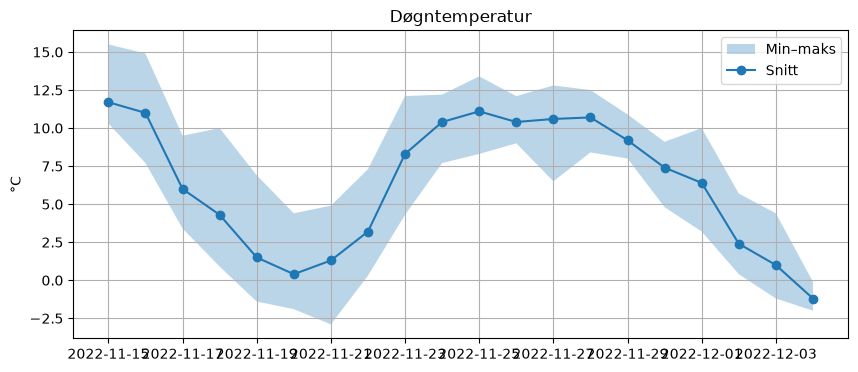

In [6]:
plt.fill_between(dogn.index, dogn["min"], dogn["max"], alpha=0.3, label="Min–maks")
plt.plot(dogn.index, dogn["mean"], marker="o", label="Snitt")
plt.title("Døgntemperatur")
plt.ylabel("°C")
plt.legend()
plt.grid()
plt.show()

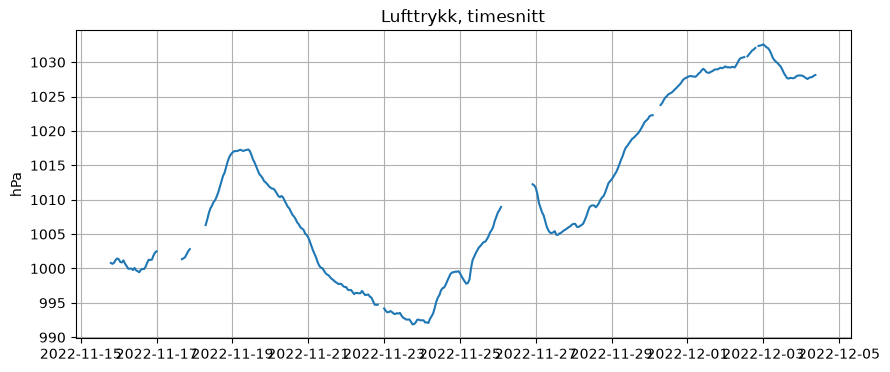

In [7]:
# Timesnitt gir ei roligare kurve enn rådata, men viser framleis variasjonen gjennom døgnet
time = data.resample("60min").mean()
plt.plot(time.index, time["lufttrykk"])
plt.title("Lufttrykk, timesnitt")
plt.ylabel("hPa")
plt.grid()
plt.show()

## 4. Døgnvariasjon med `groupby`

Er det varmare midt på dagen enn om natta? `data.index.hour` gir timen (0–23) for kvar måling. Med `groupby` samlar me alle målingar frå same time, uansett dag, og reknar ut snittet.

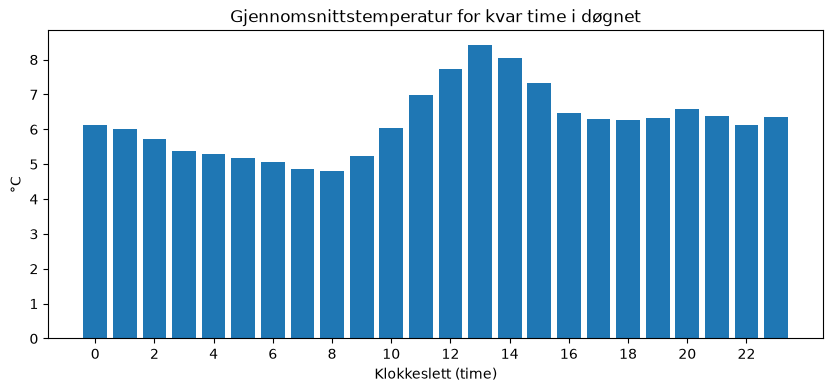

In [8]:
per_time = data.groupby(data.index.hour)["temperatur"].mean()

plt.bar(per_time.index, per_time.values)
plt.title("Gjennomsnittstemperatur for kvar time i døgnet")
plt.xlabel("Klokkeslett (time)")
plt.ylabel("°C")
plt.xticks(range(0, 24, 2))
plt.show()

## 5. Samanhengar: spreiingsplott og korrelasjon

I eit spreiingsplott er kvar måling ein prikk. Dersom prikkane dannar ei skrå linje, heng storleikane saman. **Korrelasjonskoeffisienten** er eit tal mellom −1 og 1 som seier kor sterk samanhengen er:

- nær 1: når den eine aukar, aukar den andre,
- nær −1: når den eine aukar, minkar den andre,
- nær 0: ingen (lineær) samanheng.

NB: Ein samanheng betyr ikkje nødvendigvis at det eine *fører til* det andre.

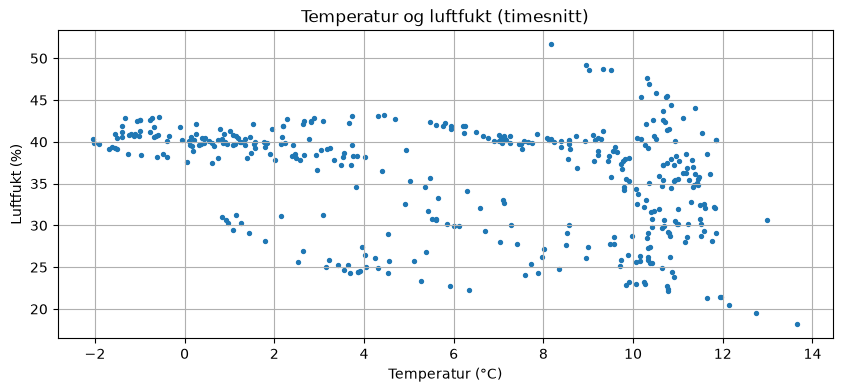

In [9]:
plt.scatter(time["temperatur"], time["luftfuktighet"], s=8)
plt.title("Temperatur og luftfukt (timesnitt)")
plt.xlabel("Temperatur (°C)")
plt.ylabel("Luftfukt (%)")
plt.grid()
plt.show()

In [10]:
data[["temperatur", "lufttrykk", "luftfuktighet", "pm25", "pm10"]].corr().round(2)

,temperatur,lufttrykk,luftfuktighet,pm25,pm10
temperatur,1.00,-0.37,-0.33,-0.46,-0.45
lufttrykk,-0.37,1.00,0.67,0.34,0.33
luftfuktighet,-0.33,0.67,1.00,0.25,0.25
pm25,-0.46,0.34,0.25,1.00,0.99
pm10,-0.45,0.33,0.25,0.99,1.00


## 6. Histogram

Eit histogram viser kor ofte ulike verdiar førekjem. Kva fortel histogrammet om svevestøvet? Er det jamt, eller er det stort sett lite med nokre få toppar?

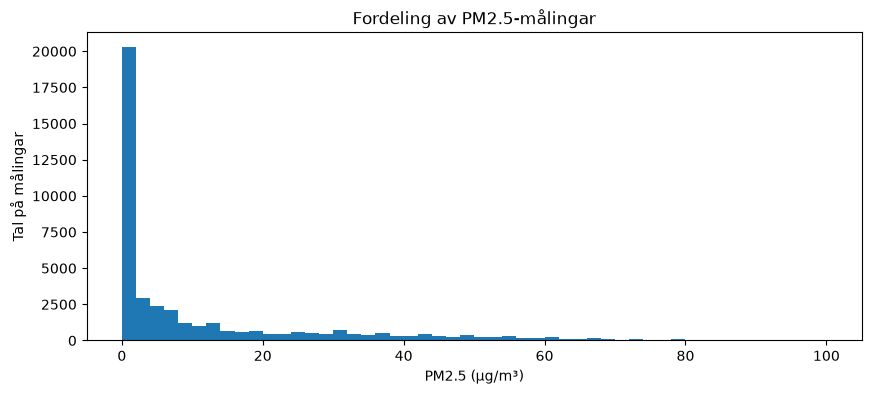

In [11]:
plt.hist(data["pm25"], bins=50, range=(0, 100))
plt.title("Fordeling av PM2.5-målingar")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Tal på målingar")
plt.show()

## 7. Samanlikne inne og ute

I mappa `øvre-kråkenes-188-inne-2022` ligg målingar frå ein stasjon som stod inne i same hus. Den fila har andre kolonnenamn (`tidspunkt`, `trykk`, `fuktighet`). Det er vanleg når data kjem frå ulike kjelder.

For å samanlikne reknar me ut timesnitt for begge, og set dei saman i éin tabell med `join`. Då får me berre dei timane der begge stasjonane har målingar.

In [12]:
inne = pd.read_csv("../øvre-kråkenes-188-inne-2022/v0-verstasjon.csv",
                   parse_dates=["tidspunkt"], index_col="tidspunkt")

inne_time = inne[["temperatur", "trykk"]].resample("60min").mean()
ute_time = data[["temperatur", "lufttrykk"]].resample("60min").mean()

# add_suffix legg til ein endelse på kolonnenamna, så me veit kva som er inne og ute
begge = inne_time.add_suffix("_inne").join(ute_time.add_suffix("_ute"), how="inner").dropna()
begge.head()

,temperatur_inne,trykk_inne,temperatur_ute,lufttrykk_ute
tidspunkt,,,,
2022-11-15 19:00:00,25.169736,1000.128813,12.977796,1000.808483
2022-11-15 20:00:00,24.977196,999.845881,11.584039,1000.679483
2022-11-15 21:00:00,24.709522,1000.007623,11.301397,1000.816531
2022-11-15 22:00:00,24.948104,1000.436860,11.837372,1001.223786
2022-11-15 23:00:00,24.906674,1000.697738,11.764599,1001.459451


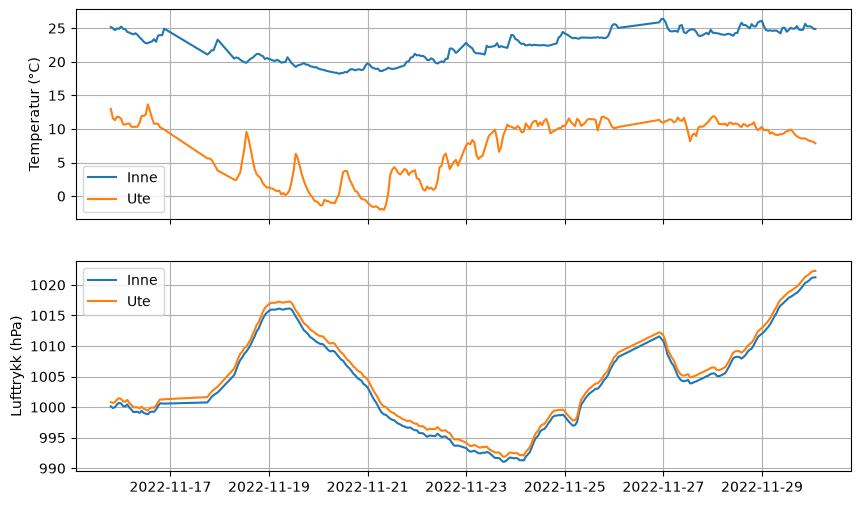

In [13]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 6))

ax1.plot(begge.index, begge["temperatur_inne"], label="Inne")
ax1.plot(begge.index, begge["temperatur_ute"], label="Ute")
ax1.set_ylabel("Temperatur (°C)")
ax1.legend()
ax1.grid()

ax2.plot(begge.index, begge["trykk_inne"], label="Inne")
ax2.plot(begge.index, begge["lufttrykk_ute"], label="Ute")
ax2.set_ylabel("Lufttrykk (hPa)")
ax2.legend()
ax2.grid()

plt.show()

Lufttrykket inne og ute burde vere nesten likt, sidan huset ikkje er lufttett. Følgjer kurvene kvarandre? Er det ein fast avstand mellom dei? Då kan det tyde på at éin av sensorane bør kalibrerast.

In [14]:
forskjell = begge["lufttrykk_ute"] - begge["trykk_inne"]
print(f"Ute minus inne, lufttrykk: snitt {forskjell.mean():.1f} hPa, standardavvik {forskjell.std():.1f} hPa")

Ute minus inne, lufttrykk: snitt 1.0 hPa, standardavvik 0.2 hPa


## 8. Lagre resultat

Figurar kan lagrast med `plt.savefig`, og tabellar med `to_csv`. Norsk Excel ventar semikolon mellom kolonnane og komma som desimalteikn, så då må me seie frå om det.

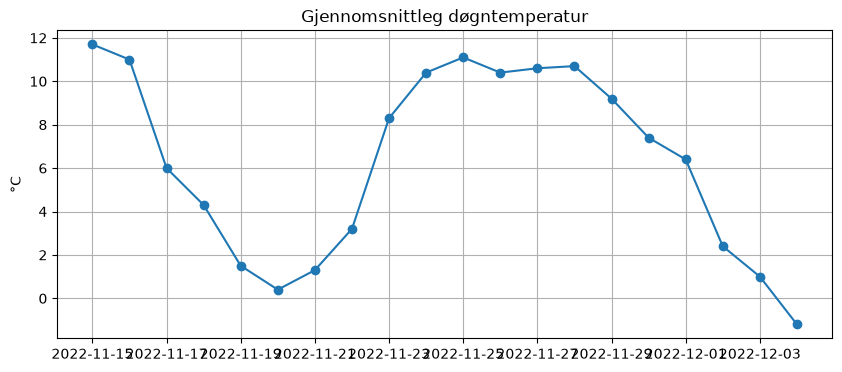

In [15]:
dogn.to_csv("dognstatistikk.csv", sep=";", decimal=",")

plt.plot(dogn.index, dogn["mean"], marker="o")
plt.title("Gjennomsnittleg døgntemperatur")
plt.ylabel("°C")
plt.grid()
plt.savefig("dogntemperatur.png", dpi=150, bbox_inches="tight")
plt.show()

## Bruke data frå din eigen verstasjon

`verstasjon.py` lagar ei CSV-fil med kolonnane `tidspunkt, temperatur, trykk, fuktighet, pm25, pm10`. Kopier fila hit og les ho inn slik:

```python
data = pd.read_csv("verstasjon.csv", parse_dates=["tidspunkt"], index_col="tidspunkt")
```

Hugs å bruke dei nye kolonnenamna (`trykk` og `fuktighet`) i resten av koden.